# Imbalance Bars as Stopping Times

The tick rule assigns a direction to each price record, then forms signed tick, volume, or dollar contributions:

$$
b_i=\begin{cases}b_{i-1},&\Delta p_i=0,\\ \operatorname{sign}(\Delta p_i),&\Delta p_i\neq0,\end{cases}
\qquad x_i\in\{b_i,b_iv_i,b_ip_iv_i\}.
$$

Here, $b_i$ is the assigned direction; $\Delta p_i=p_i-p_{i-1}$ is the price change; $b_{i-1}$ carries direction through a zero change. $\operatorname{sign}$ returns the sign of a nonzero change; $x_i$ is the chosen signed contribution; $v_i$ is volume; $p_i$ is price.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("05_event_based_financial_time");
using CSV, Printf
using RiskLabAI.Data: StandardBars,TimeBars,FixedImbalanceBars,ExpectedImbalanceBars,FixedRunBars,ExpectedRunBars,Tick,Volume,Dollar,construct_bars_from_data
using RiskLabAI.Utils: CUMULATIVE_TICKS,CUMULATIVE_THETA,EXPECTED_IMBALANCE,EXPECTED_TICKS_NUMBER,CUMULATIVE_BUY_THETA,CUMULATIVE_SELL_THETA,EXPECTED_BUY_IMBALANCE,EXPECTED_SELL_IMBALANCE,EXPECTED_BUY_TICKS_PROPORTION
raw_all = load_binance()
raw = first(raw_all,10080)
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
observations = select(raw,:time,:close,:volume)
bar_columns = ["Time","Last record","Open","High","Low","Close","Volume","Buy volume","Sell volume","Records","Dollar value","Rule level"]

function bar_frame(rows)
    return DataFrame([name=>(j==1 ? DateTime[row[j] for row in rows] : j in (2,10) ? Int[row[j] for row in rows] : Float64[row[j] for row in rows]) for (j,name) in enumerate(bar_columns)])
end

function history_frame(rule,names)
    history = rule.analyse_thresholds
    columns = Pair["Record"=>collect(eachindex(history))]
    append!(columns,[name=>Float64[row[name] for row in history] for name in names])
    return DataFrame(columns)
end


history_frame (generic function with 1 method)

## The Tick Rule

Cumulative imbalance is the running sum of signed contributions through record $n.$:

$$
\theta_n=\sum_{i=1}^{n}x_i.
$$

Here, $\theta_n$ is cumulative imbalance; $x_i$ is the signed contribution from record $i$; $i$ labels records; $n$ is the current record count.

In [2]:
example_prices = [100.,101.,101.,100.,100.,102.,101.,101.]
example_moves = vcat(0.,diff(example_prices))
example_signs = zeros(Int,length(example_prices))
prior_sign = 0
for (position,move) in enumerate(example_moves)
    move!=0 && (prior_sign=Int(sign(move)))
    example_signs[position] = prior_sign
end
tick_rule_example = DataFrame("Record"=>collect(eachindex(example_prices)),"Price"=>example_prices,"Price change"=>example_moves,"Carried sign"=>example_signs,"Cumulative imbalance"=>cumsum(example_signs))
save_table(tick_rule_example,paths,"tick_rule_example";caption="The tick rule carries the last nonzero sign across an unchanged price.",label="tab:tick-rule-example")


Row,Record,Price,Price change,Carried sign,Cumulative imbalance
,Int64,Float64,Float64,Int64,Int64
1,1,100.0,0.0,0,0
2,2,101.0,1.0,1,1
3,3,101.0,0.0,1,2
4,4,100.0,-1.0,-1,1
5,5,100.0,0.0,-1,0
6,6,102.0,2.0,1,1
7,7,101.0,-1.0,-1,0
8,8,101.0,0.0,-1,-1


## First Crossing

The bar closes at the first record where absolute cumulative imbalance reaches its expected scale:

$$
\tau=\inf\left\{n\geq1:|\theta_n|\geq \widehat T\,|\widehat\mu_x|\right\}.
$$

Here, $\tau$ is the closing record; $n$ is a candidate record count; $\theta_n$ is cumulative imbalance. $\widehat T$ is expected bar length; $\widehat\mu_x$ is expected signed contribution per record; $\inf$ selects the first crossing.

Recent signed contributions receive more weight when estimating their current mean:

$$
\widehat\mu_{x,t}=\frac{x_t+q x_{t-1}+\cdots+q^t x_0}{1+q+\cdots+q^t},\qquad
q=1-\frac{2}{w+1}.
$$

Here, $\widehat\mu_{x,t}$ is the weighted mean at time $t$; $x_t,\ldots,x_0$ are present and past contributions. $q\in(0,1)$ is the weight decay factor; $w$ is the chosen span; $q^j$ is the weight on a contribution $j$ steps old.

In [3]:
fixed_rule = FixedImbalanceBars{Tick}(;bar_type="tick_imbalance",initial_estimate_of_expected_n_ticks_in_bar=60.,expected_imbalance_window=120,does_analyse_thresholds=true)
expected_rule = ExpectedImbalanceBars{Tick}(;bar_type="tick_imbalance",window_size_for_expected_n_ticks_estimation=20,initial_estimate_of_expected_n_ticks_in_bar=60.,expected_imbalance_window=240,expected_ticks_number_bounds=(20.,180.),does_analyse_thresholds=true)
fixed_bars = bar_frame(construct_bars_from_data(fixed_rule;data=observations))
expected_bars = bar_frame(construct_bars_from_data(expected_rule;data=observations))
history_names = [CUMULATIVE_THETA,CUMULATIVE_TICKS,EXPECTED_IMBALANCE,EXPECTED_TICKS_NUMBER]
fixed_history,expected_history = history_frame(fixed_rule,history_names),history_frame(expected_rule,history_names)
summary_rows = [(;rule=name,complete=nrow(frame),smallest=minimum(frame.Records),middle=median(frame.Records),largest=maximum(frame.Records),level=median(frame[!,"Rule level"])) for (name,frame) in [("Fixed expected length",fixed_bars),("Updated expected length",expected_bars)]]
imbalance_bar_summary = DataFrame(summary_rows)
rename!(imbalance_bar_summary,["Rule","Complete bars","Smallest record count","Middle record count","Largest record count","Middle rule level"])
save_table(imbalance_bar_summary,paths,"imbalance_bar_summary";caption="Tick-imbalance bars formed from the one-week illustration.",label="tab:imbalance-bar-summary")
save_data(fixed_bars,paths,"fixed_imbalance_bars")
save_data(expected_bars,paths,"expected_imbalance_bars")
save_data(fixed_history,paths,"fixed_imbalance_history")
save_data(expected_history,paths,"expected_imbalance_history");


Row,Rule,Complete bars,Smallest record count,Middle record count,Largest record count,Middle rule level
,String,Int64,Int64,Float64,Int64,Float64
1,Fixed expected length,158,1,23.0,578,5.04581
2,Updated expected length,26,8,192.0,1881,13.3508


In [4]:
close_positions = fixed_bars[!,"Last record"]
close_crossings,previous_steps_below,gaps = Bool[],Bool[],Float64[]
bar_start = 1
for close_position in close_positions
    row = fixed_history[close_position,:]
    boundary = row[EXPECTED_TICKS_NUMBER]*abs(row[EXPECTED_IMBALANCE])
    push!(close_crossings,abs(row[CUMULATIVE_THETA])>=boundary)
    if close_position>bar_start
        prior = fixed_history[close_position-1,:]
        prior_boundary = prior[EXPECTED_TICKS_NUMBER]*abs(prior[EXPECTED_IMBALANCE])
        push!(previous_steps_below,abs(prior[CUMULATIVE_THETA])<prior_boundary)
        push!(gaps,prior_boundary-abs(prior[CUMULATIVE_THETA]))
    end
    bar_start = close_position+1
end
stopping_check = DataFrame("Check"=>["Completed bars cross their rule","Immediately preceding records remain below the rule","Smallest preceding gap"],"Result"=>[string(sum(close_crossings)," of ",length(close_crossings)),string(sum(previous_steps_below)," of ",length(previous_steps_below)),@sprintf("%.6f",minimum(gaps))])
save_table(stopping_check,paths,"imbalance_stopping_check";caption="Checks of the first-crossing rule for fixed tick-imbalance bars.",label="tab:imbalance-stopping-check")


Row,Check,Result
,String,String
1,Completed bars cross their rule,158 of 158
2,Immediately preceding records remain below the rule,138 of 138
3,Smallest preceding gap,0.017148


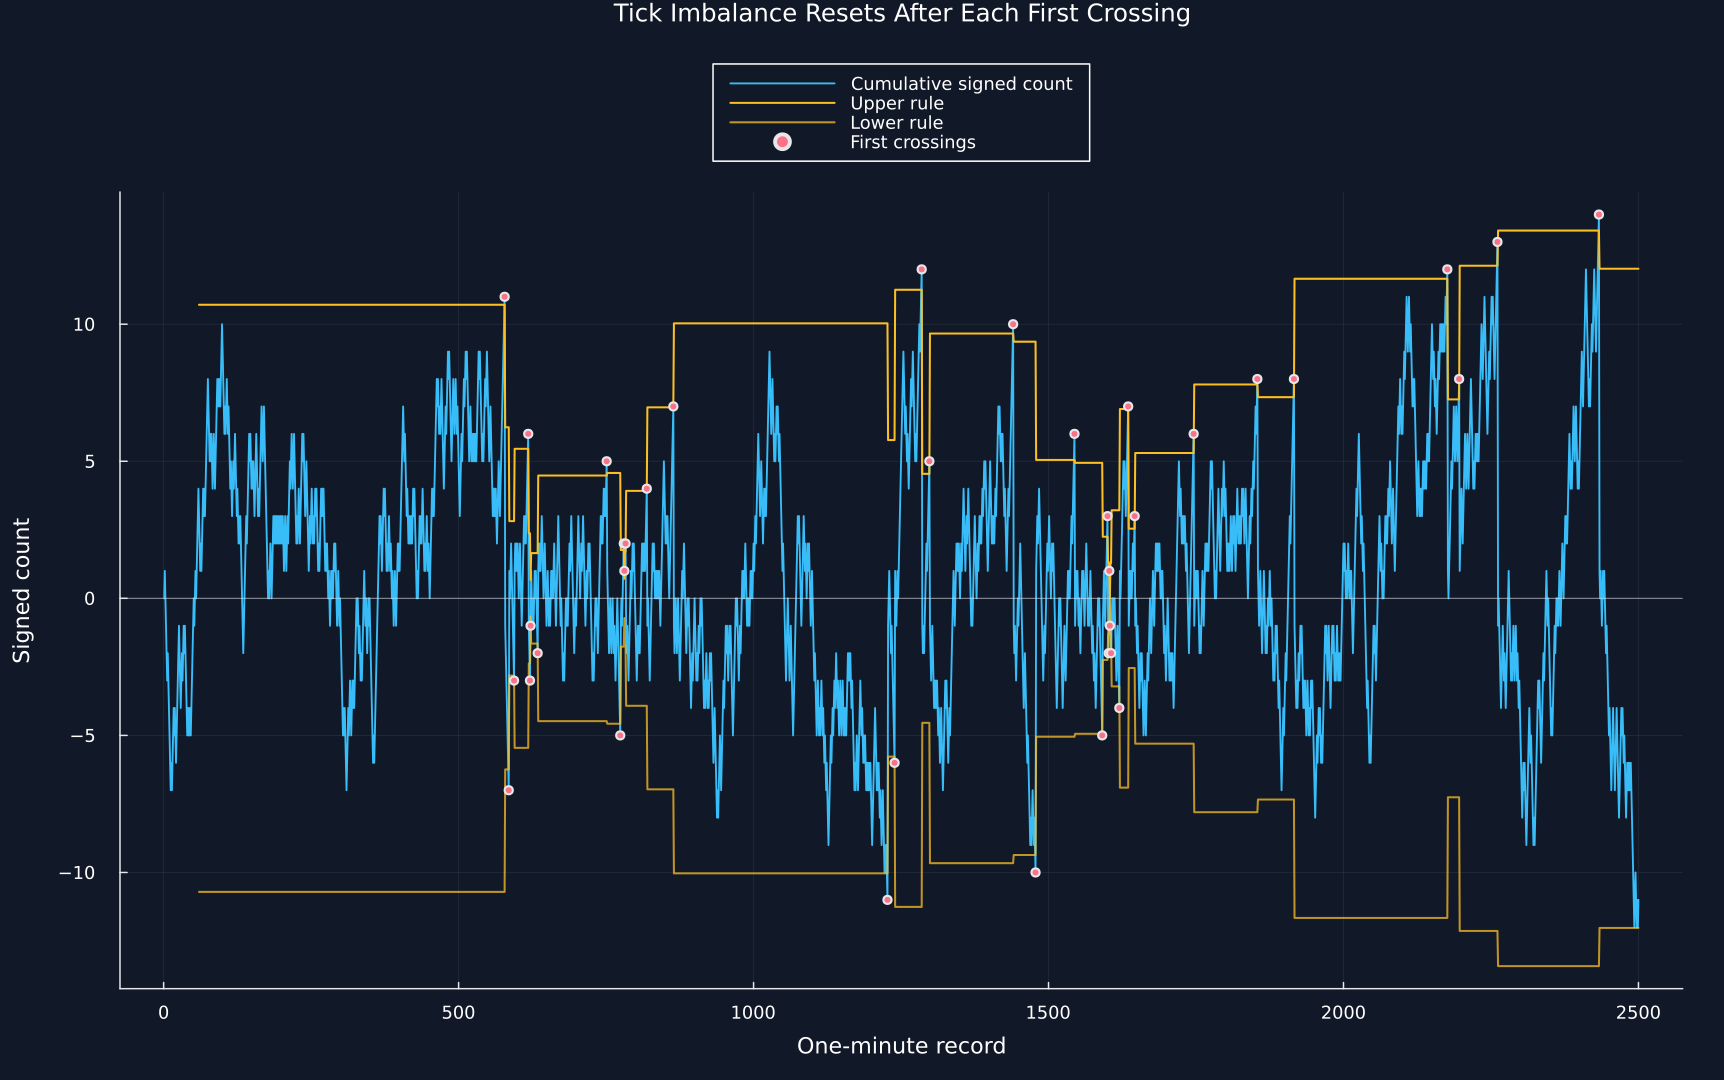

In [5]:
visible = first(fixed_history,2500)
boundary = visible[!,EXPECTED_TICKS_NUMBER].*abs.(visible[!,EXPECTED_IMBALANCE])
visible_closes = close_positions[close_positions.<=nrow(visible)]
figure = plot(visible.Record,visible[!,CUMULATIVE_THETA];color=palette.cyan,linewidth=1.25,label="Cumulative signed count",xlabel="One-minute record",ylabel="Signed count",title="Tick Imbalance Resets After Each First Crossing",legend=:outertop,size=(1150,720))
plot!(figure,visible.Record,boundary;color=palette.amber,linewidth=1.35,label="Upper rule")
plot!(figure,visible.Record,-boundary;color=palette.amber,linewidth=1.35,alpha=.75,label="Lower rule")
scatter!(figure,visible_closes,fixed_history[visible_closes,CUMULATIVE_THETA];color=palette.rose,markersize=3,label="First crossings")
hline!(figure,[0.];color=palette.text,linewidth=.7,alpha=.55,label=false)
save_figure(figure,paths,"imbalance_first_crossings")


## Updating expected bar length

Expected bar length is either held at its starting value or updated from earlier observed bar lengths within chosen bounds:

$$
\widehat T_k^{\mathrm{fixed}}=T_0,\qquad
\widehat T_k^{\mathrm{updated}}=\operatorname{clip}\!\left(\operatorname{EWMA}(T_1,\ldots,T_{k-1}),T_{\min},T_{\max}\right).
$$

Here, $\widehat T_k$ is expected length for bar $k$; $T_0$ is the fixed starting length; $T_1,\ldots,T_{k-1}$ are earlier lengths. $\operatorname{EWMA}$ is an exponentially weighted mean; $T_{\min}$ and $T_{\max}$ are lower and upper bounds; $\operatorname{clip}$ enforces them.

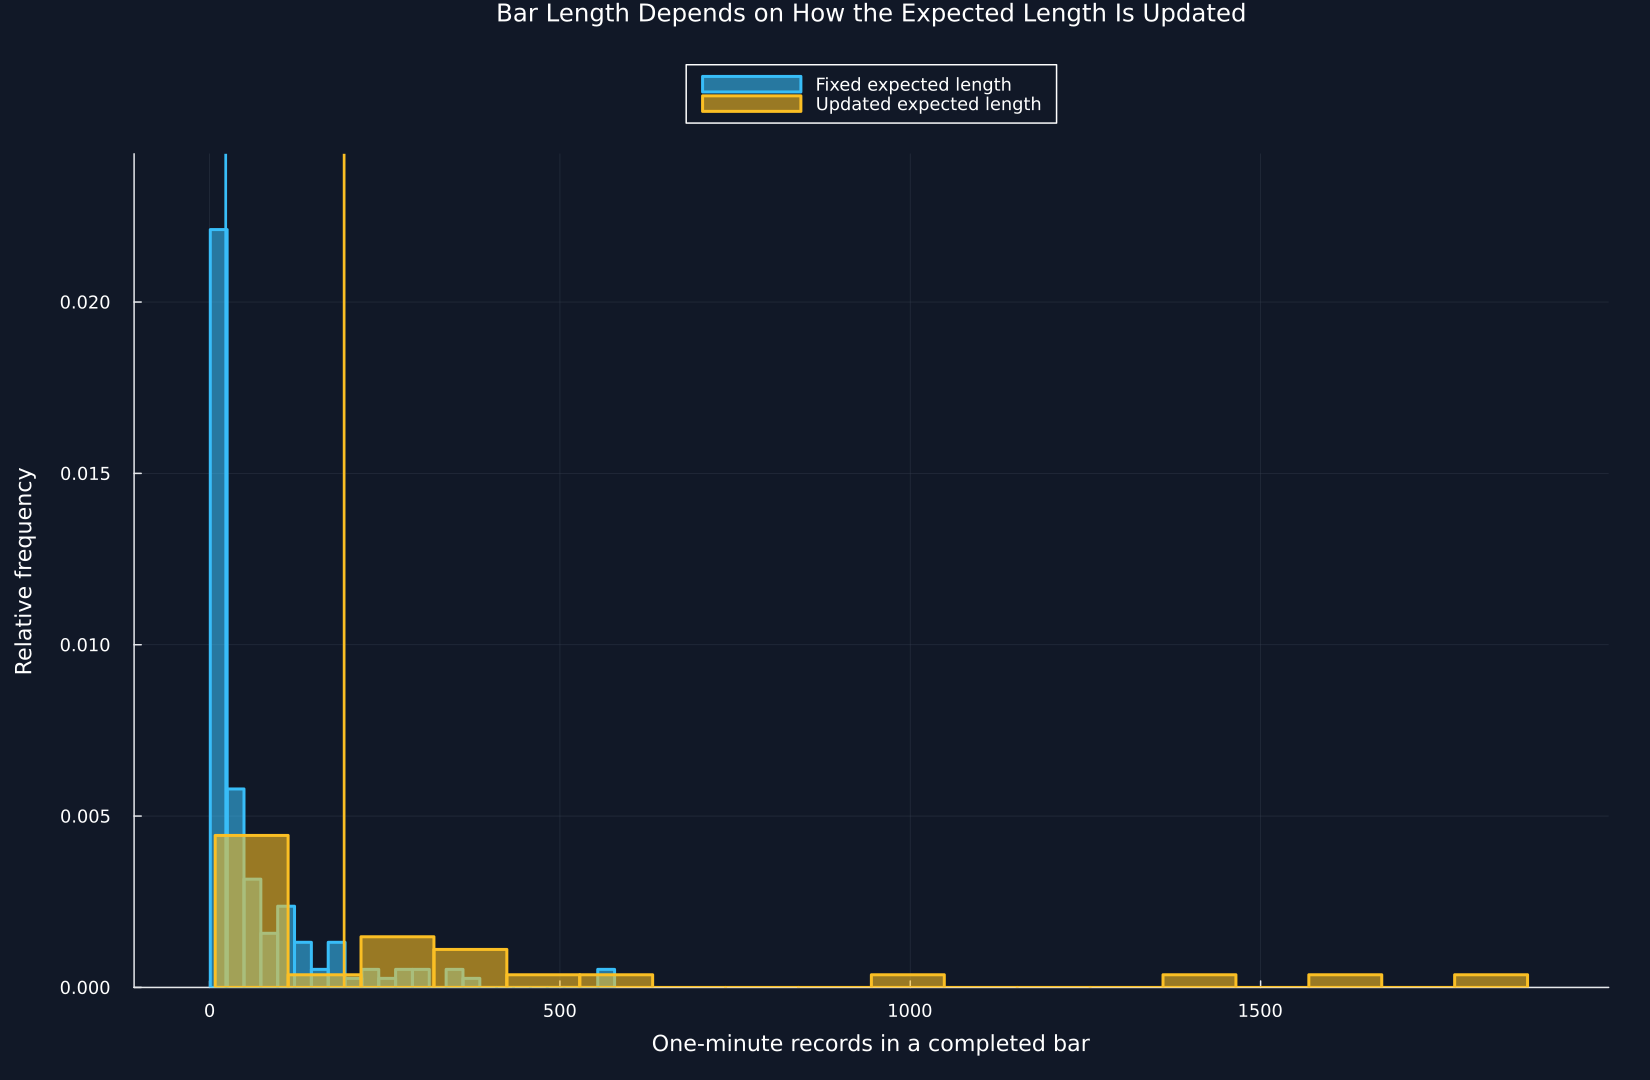

In [6]:
figure = plot(;xlabel="One-minute records in a completed bar",ylabel="Relative frequency",title="Bar Length Depends on How the Expected Length Is Updated",legend=:outertop,size=(1100,720))
maximum_density = 0.
for (frame,bins,color,label) in [(fixed_bars,24,palette.cyan,"Fixed expected length"),(expected_bars,18,palette.amber,"Updated expected length")]
    edges = collect(range(minimum(frame.Records),maximum(frame.Records);length=bins+1))
    counts = [count(value->edges[index]<=value && (value<edges[index+1] || index==bins && value==edges[end]),frame.Records) for index in 1:bins]
    density = counts./(nrow(frame).*diff(edges))
    maximum_density = max(maximum_density,maximum(density))
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,density;bar_width=diff(edges),color,fillalpha=.58,linecolor=color,label)
    save_data(DataFrame("Left edge"=>edges[1:end-1],"Right edge"=>edges[2:end],"Count"=>counts,"Density"=>density),paths,label=="Fixed expected length" ? "fixed_imbalance_length_histogram" : "expected_imbalance_length_histogram")
    vline!(figure,[median(frame.Records)];color,linewidth=1.8,label=false)
end
ylims!(figure,0.,1.1maximum_density)
save_figure(figure,paths,"imbalance_bar_lengths")


## Tests

In [7]:
@assert example_signs == [0,1,1,-1,-1,1,-1,-1]
@assert tick_rule_example[!,"Cumulative imbalance"] == [0,1,2,1,0,1,0,-1]
@assert nrow(fixed_history) == nrow(raw)
@assert nrow(expected_history) == nrow(raw)
@assert nrow(fixed_bars) == 158
@assert nrow(expected_bars) == 26
@assert all(close_crossings)
@assert all(previous_steps_below)
@assert minimum(gaps) > 0
@assert all(diff(close_positions).>0)
@assert maximum(fixed_bars[!,"Last record"]) <= nrow(raw)
@assert maximum(expected_bars[!,"Last record"]) <= nrow(raw)
@assert minimum(fixed_bars.Records) >= 1
@assert minimum(expected_bars.Records) >= 1
@assert all(fixed_bars[!,"Rule level"].>0)
@assert all(expected_bars[!,"Rule level"].>0)
@assert all(filter(isfinite,fixed_history[!,EXPECTED_TICKS_NUMBER]).==60)
@assert all(20 .<= filter(isfinite,expected_history[!,EXPECTED_TICKS_NUMBER]) .<= 180)
@assert isfile(joinpath(paths.figures,"imbalance_first_crossings.pdf"))
@assert isfile(joinpath(paths.figures,"imbalance_bar_lengths.pdf"))
@assert isfile(joinpath(paths.tables,"tick_rule_example.tex"))
@assert isfile(joinpath(paths.tables,"imbalance_bar_summary.tex"))
@assert isfile(joinpath(paths.tables,"imbalance_stopping_check.tex"))
